# PDF 파싱 도구 비교 및 데이터 구조 분석
- 목적: 개발용 PDF의 텍스트·표·P/N 배치 구조를 비교하고 파싱 방식을 검토함.
- 대상: 목록에 등록된 T55·TCJ·TPB 개발용 문서만 사용함.
- 처리 내용: 전체 페이지 텍스트와 선정 페이지의 기본 설정 표 추출을 두 도구로 비교함.
- 제한: 평가용 PDF를 열지 않으며 규격 정답·단위 변환·자동 P/N 규격 검증은 수행하지 않음.
- 실행 방법: 프로젝트 루트에서 `Python (datasheet-assistant)` 커널로 처음부터 순차 실행함.
- 검증 구분: 저장된 출력은 Codex 실행 결과이며 사용자 직접 실행·검증은 별도로 필요함.

In [1]:
import hashlib
import importlib.metadata as metadata
import json
import platform
import re
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import pdfplumber
import pymupdf
from IPython.display import Image, JSON, display

PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / 'data'
RESULTS_DIR = PROJECT_ROOT / 'results'
OUTPUTS_DIR = PROJECT_ROOT / 'outputs'
SELECTED_IDS = ('vishay_t55', 'kyocera_avx_tcj', 'panasonic_tpb')
TABLE_PAGES = {'vishay_t55': (1, 2, 5), 'kyocera_avx_tcj': (1, 6, 7), 'panasonic_tpb': (1,)}
REPEATS = 3
TOOLS = ('PyMuPDF', 'pdfplumber')

if not (DATA_DIR / 'datasheet_manifest.csv').is_file():
    raise FileNotFoundError(f'프로젝트 루트에서 실행 필요함: {PROJECT_ROOT}')
for directory in (RESULTS_DIR, OUTPUTS_DIR):
    if not directory.is_dir():
        raise FileNotFoundError(f'기존 폴더 확인 필요함: {directory}')

environment = pd.DataFrame([
    {'item': 'Python', 'value': platform.python_version()},
    {'item': 'Python executable', 'value': sys.executable},
    {'item': 'PyMuPDF', 'value': metadata.version('pymupdf')},
    {'item': 'pdfplumber', 'value': metadata.version('pdfplumber')},
    {'item': 'Project root', 'value': str(PROJECT_ROOT)},
    {'item': 'Repeats', 'value': str(REPEATS)},
])
display(environment)
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', 130)

,item,value
0,Python,3.12.6
1,Python executable,d:\datasheet-assistant\.venv\Scripts\python.exe
2,PyMuPDF,2.1
3,pdfplumber,0.11.10
4,Project root,D:\datasheet-assistant
5,Repeats,3


## 실험 데이터 선정
- CSV 3종의 문서 식별자·분리 정보가 일치하는지 먼저 확인함.
- 개발용 문서 목록은 CSV에서 확인하며 실제 PDF 열기는 선정 문서로 제한함.
- 파일명은 manifest에서 읽으며 평가용 파일 검색·열기를 수행하지 않음.

In [2]:
manifest = pd.read_csv(DATA_DIR / 'datasheet_manifest.csv', dtype=str, keep_default_na=False)
part_numbers = pd.read_csv(DATA_DIR / 'part_numbers.csv', dtype=str, keep_default_na=False)
dataset_split = pd.read_csv(DATA_DIR / 'dataset_split.csv', dtype=str, keep_default_na=False)
required = [
    (manifest, {'document_id', 'manufacturer', 'series', 'filename', 'page_count', 'split', 'notes'}),
    (part_numbers, {'document_id', 'part_number', 'split'}),
    (dataset_split, {'document_id', 'manufacturer', 'series', 'split'}),
]
for frame, columns in required:
    if not columns.issubset(frame.columns):
        raise ValueError(f'CSV 필수 컬럼 누락됨: {columns - set(frame.columns)}')
if manifest.document_id.duplicated().any() or dataset_split.document_id.duplicated().any():
    raise ValueError('문서 식별자 중복됨')
if part_numbers.part_number.duplicated().any():
    raise ValueError('대상 P/N 중복됨')
if set(manifest.document_id) != set(dataset_split.document_id):
    raise ValueError('manifest와 split 문서 식별자가 다름')
if not set(part_numbers.document_id).issubset(set(manifest.document_id)):
    raise ValueError('P/N 목록에 알 수 없는 문서가 있음')
for frame in (dataset_split, part_numbers):
    joined = frame.merge(manifest, on='document_id', suffixes=('_item', '_manifest'), validate='many_to_one')
    for column in ('manufacturer', 'series', 'split'):
        if column + '_item' in joined and not joined[column + '_item'].eq(joined[column + '_manifest']).all():
            raise ValueError(f'CSV 간 {column} 정보가 다름')
if manifest.groupby(['manufacturer', 'series'])['split'].nunique().max() != 1:
    raise ValueError('같은 시리즈가 양쪽 세트에 있음')
selected = manifest.set_index('document_id').loc[list(SELECTED_IDS)].reset_index()
selected_parts = part_numbers[part_numbers.document_id.isin(SELECTED_IDS)].copy()
if not selected.split.eq('dev').all() or not selected_parts.split.eq('dev').all():
    raise ValueError('선정 대상에 개발용이 아닌 문서가 있음')
if set(selected_parts.document_id) != set(SELECTED_IDS):
    raise ValueError('선정 문서에 대상 P/N이 누락됨')
paths = {}
for row in selected.itertuples():
    path = (DATA_DIR / 'datasheets' / row.filename).resolve()
    if path.parent != (DATA_DIR / 'datasheets').resolve() or not path.is_file():
        raise FileNotFoundError(f'선정 PDF 경로 확인 필요함: {path}')
    paths[row.document_id] = path
protected_paths = [DATA_DIR / name for name in ('datasheet_manifest.csv', 'part_numbers.csv', 'dataset_split.csv')]
protected_paths += list(paths.values())
source_hashes = {str(path): hashlib.sha256(path.read_bytes()).hexdigest() for path in protected_paths}
for row in selected.itertuples():
    match = re.search(r'SHA256=([a-f0-9]{64})', row.notes)
    if match and source_hashes[str(paths[row.document_id])] != match.group(1):
        raise ValueError(f'수집 시점과 PDF 해시가 다름: {row.document_id}')
display(manifest.loc[manifest.split.eq('dev'), ['document_id', 'manufacturer', 'series', 'page_count']])
display(selected[['document_id', 'manufacturer', 'series', 'page_count', 'split']])
display(selected_parts[['document_id', 'part_number', 'selection_note']])

,document_id,manufacturer,series,page_count
0,vishay_293d,Vishay,293D,13
2,vishay_t55,Vishay,T55,30
4,kyocera_avx_taj,KYOCERA AVX,TAJ,13
5,kyocera_avx_tps,KYOCERA AVX,TPS,12
6,kyocera_avx_tcj,KYOCERA AVX,TCJ,13
8,panasonic_tpb,Panasonic,TPB,1


,document_id,manufacturer,series,page_count,split
0,vishay_t55,Vishay,T55,30,dev
1,kyocera_avx_tcj,KYOCERA AVX,TCJ,13,dev
2,panasonic_tpb,Panasonic,TPB,1,dev


,document_id,part_number,selection_note
2,vishay_t55,T55A226M2R5C0200,PDF 5쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
3,vishay_t55,T55A336M2R5C0200,PDF 5쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
4,vishay_t55,T55B107M2R5C0070,PDF 5쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
9,kyocera_avx_tcj,TCJU337M016R0050E,PDF 6쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
10,kyocera_avx_tcj,TCJU337M016R0070E,PDF 6쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
11,kyocera_avx_tcj,TCJU227M020R0070E,PDF 6쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
12,kyocera_avx_tcj,TCJU107M025R0070E,PDF 7쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
14,panasonic_tpb,4TPB68M,PDF 1쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
15,panasonic_tpb,6TPB220ML,PDF 1쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음
16,panasonic_tpb,10TPB150ML,PDF 1쪽 규격표의 완전한 P/N을 원문 화면과 대조해 선정함; 자리표시자 치환하지 않음


## 비교 조건
- 동일 문서·전체 페이지를 텍스트 비교 대상으로 사용함.
- 표 비교 대상은 T55 1·2·5쪽, TCJ 1·6·7쪽, TPB 1쪽으로 고정함.
- PyMuPDF 텍스트는 `get_text('text')`, 표는 `find_tables()` 후 `extract()` 사용함.
- pdfplumber 텍스트는 `extract_text()`, 표는 `extract_tables()` 사용함.
- 두 도구 모두 기본 설정을 사용하며 좌표·셀 경계·행 데이터를 임의 보정하지 않음.
- 매 회차 새 문서를 열고 도구 실행 순서를 번갈아 배치함. 페이지 추출 시간과 문서 전체 텍스트 처리 시간을 구분함.
- 시간에는 출력·그래프·원문 렌더링을 포함하지 않음. 표 시간은 감지와 셀 텍스트 변환을 포함함.
- 같은 컴퓨터에서 3회 반복한 중앙값을 표시함. 캐시·실행 순서·문서 구조에 영향을 받으므로 일반 성능으로 확대 해석하지 않음.
- 성공 페이지는 예외 없이 비어 있지 않은 텍스트가 반환된 페이지임. 내용 정확도를 의미하지 않음.
- [PyMuPDF 공식 API](https://pymupdf.readthedocs.io/en/latest/page.html#Page.find_tables)와 [pdfplumber 공식 API](https://github.com/jsvine/pdfplumber#extracting-tables) 참고함.

In [3]:
def run_text_trial(document_id, path, tool, trial):
    """페이지별 원문 텍스트와 시간을 측정함."""
    records = []
    extracted = {}
    started_document = perf_counter()
    opener = pymupdf.open if tool == 'PyMuPDF' else pdfplumber.open
    with opener(path) as document:
        pages = document if tool == 'PyMuPDF' else document.pages
        for page_number, page in enumerate(pages, start=1):
            started_page = perf_counter()
            try:
                text = page.get_text('text') if tool == 'PyMuPDF' else page.extract_text()
            except Exception as error:
                raise RuntimeError(f'텍스트 추출 실패함: {document_id}, {tool}, {page_number}쪽') from error
            elapsed = perf_counter() - started_page
            text = text or ''
            extracted[page_number] = text
            records.append({'document_id': document_id, 'tool': tool, 'trial': trial,
                            'page': page_number, 'text_characters': len(text),
                            'text_success': bool(text.strip()), 'text_seconds': elapsed})
    return records, extracted, perf_counter() - started_document


def run_table_trial(document_id, path, tool, trial):
    """고정된 페이지의 기본 설정 표 추출을 측정함."""
    records = []
    extracted = {}
    opener = pymupdf.open if tool == 'PyMuPDF' else pdfplumber.open
    with opener(path) as document:
        for page_number in TABLE_PAGES[document_id]:
            page = document[page_number - 1] if tool == 'PyMuPDF' else document.pages[page_number - 1]
            started_page = perf_counter()
            try:
                if tool == 'PyMuPDF':
                    finder = page.find_tables()
                    tables = [{'rows': table.extract(), 'header_names': table.header.names,
                               'header_external': table.header.external} for table in finder.tables]
                else:
                    tables = [{'rows': rows, 'header_names': None, 'header_external': None}
                              for rows in page.extract_tables()]
            except Exception as error:
                raise RuntimeError(f'표 추출 실패함: {document_id}, {tool}, {page_number}쪽') from error
            elapsed = perf_counter() - started_page
            extracted[page_number] = tables
            records.append({'document_id': document_id, 'tool': tool, 'trial': trial,
                            'page': page_number, 'table_count': len(tables), 'table_seconds': elapsed})
    return records, extracted

In [4]:
text_trials = []
table_trials = []
document_trials = []
text_cache = {}
table_cache = {}
for trial in range(1, REPEATS + 1):
    trial_tools = TOOLS if trial % 2 else tuple(reversed(TOOLS))
    for document_id in SELECTED_IDS:
        for tool in trial_tools:
            records, texts, document_seconds = run_text_trial(document_id, paths[document_id], tool, trial)
            text_trials.extend(records)
            document_trials.append({'document_id': document_id, 'tool': tool, 'trial': trial,
                                    'text_document_seconds': document_seconds})
            records, tables = run_table_trial(document_id, paths[document_id], tool, trial)
            table_trials.extend(records)
            if trial == 1:
                for page, text in texts.items():
                    text_cache[(document_id, tool, page)] = text
                for page, table_list in tables.items():
                    table_cache[(document_id, tool, page)] = table_list
    print(f'{trial}회차 추출 완료함')
text_trials = pd.DataFrame(text_trials)
table_trials = pd.DataFrame(table_trials)
document_trials = pd.DataFrame(document_trials)
page_metrics = text_trials.groupby(['document_id', 'tool', 'page'], as_index=False).agg(
    text_characters=('text_characters', 'first'), text_success=('text_success', 'all'),
    text_seconds_median=('text_seconds', 'median'), text_seconds_min=('text_seconds', 'min'),
    text_seconds_max=('text_seconds', 'max'), character_count_variants=('text_characters', 'nunique'))
table_metrics = table_trials.groupby(['document_id', 'tool', 'page'], as_index=False).agg(
    table_count=('table_count', 'first'), table_seconds_median=('table_seconds', 'median'),
    table_count_variants=('table_count', 'nunique'))
for row in selected.itertuples():
    expected_pages = int(row.page_count)
    for tool in TOOLS:
        actual_pages = len(page_metrics[(page_metrics.document_id == row.document_id) & (page_metrics.tool == tool)])
        if actual_pages != expected_pages:
            raise ValueError(f'페이지 수가 manifest와 다름: {row.document_id}, {tool}')
display(page_metrics)
empty_pages = page_metrics.loc[~page_metrics.text_success, ['document_id', 'tool', 'page']]
print('빈 텍스트 페이지 목록임')
display(empty_pages)
print('반복 간 문자 수 또는 표 개수가 달라진 페이지 목록임')
display(page_metrics.loc[page_metrics.character_count_variants > 1])
display(table_metrics.loc[table_metrics.table_count_variants > 1])

1회차 추출 완료함
2회차 추출 완료함
3회차 추출 완료함


,document_id,tool,page,text_characters,text_success,text_seconds_median,text_seconds_min,text_seconds_max,character_count_variants
0,kyocera_avx_tcj,PyMuPDF,1,4733,True,0.017708,0.015504,0.021630,1
1,kyocera_avx_tcj,PyMuPDF,2,3226,True,0.003835,0.003790,0.003997,1
2,kyocera_avx_tcj,PyMuPDF,3,5314,True,0.007896,0.007699,0.008807,1
3,kyocera_avx_tcj,PyMuPDF,4,5666,True,0.008954,0.008947,0.015564,1
4,kyocera_avx_tcj,PyMuPDF,5,5507,True,0.007745,0.007497,0.008647,1
5,kyocera_avx_tcj,PyMuPDF,6,5501,True,0.008894,0.008797,0.008928,1
6,kyocera_avx_tcj,PyMuPDF,7,5430,True,0.007793,0.007736,0.008576,1
7,kyocera_avx_tcj,PyMuPDF,8,1895,True,0.003138,0.002813,0.003193,1
8,kyocera_avx_tcj,PyMuPDF,9,1409,True,0.004695,0.004014,0.005029,1
9,kyocera_avx_tcj,PyMuPDF,10,2232,True,0.002477,0.002457,0.002536,1


빈 텍스트 페이지 목록임


,document_id,tool,page


반복 간 문자 수 또는 표 개수가 달라진 페이지 목록임


,document_id,tool,page,text_characters,text_success,text_seconds_median,text_seconds_min,text_seconds_max,character_count_variants


,document_id,tool,page,table_count,table_seconds_median,table_count_variants


## 텍스트 및 P/N 위치
- 페이지 번호는 PDF 파일의 1부터 시작하는 페이지 번호임. 인쇄된 카탈로그 쪽수와 구분함.
- 완전한 P/N 문자열 검색과 공백 제거 후 검색을 구분함.
- 탐지 수는 고유 P/N 수이며 같은 P/N의 반복 출현 횟수와 다름.
- 문자열 탐지는 후보 위치 확인용임. 규격값·적용 범위의 검증 통과를 의미하지 않음.

In [5]:
pn_records = []
for part in selected_parts.itertuples():
    for tool in TOOLS:
        for page in range(1, int(selected.set_index('document_id').loc[part.document_id, 'page_count']) + 1):
            text = text_cache[(part.document_id, tool, page)]
            exact = part.part_number in text
            compact = part.part_number in re.sub(r'\s+', '', text)
            if exact or compact:
                pn_records.append({'document_id': part.document_id, 'tool': tool, 'part_number': part.part_number,
                                   'page': page, 'exact_match': exact, 'whitespace_removed_match': compact})
pn_columns = ['document_id', 'tool', 'part_number', 'page', 'exact_match', 'whitespace_removed_match']
pn_locations = pd.DataFrame(pn_records, columns=pn_columns)
display(pn_locations)
missing_records = []
for document_id in SELECTED_IDS:
    expected = set(selected_parts.loc[selected_parts.document_id.eq(document_id), 'part_number'])
    for tool in TOOLS:
        found = set(pn_locations.loc[pn_locations.document_id.eq(document_id) & pn_locations.tool.eq(tool), 'part_number'])
        for part_number in sorted(expected - found):
            missing_records.append({'document_id': document_id, 'tool': tool, 'part_number': part_number})
print('탐지되지 않은 대상 P/N 목록임')
display(pd.DataFrame(missing_records, columns=['document_id', 'tool', 'part_number']))

,document_id,tool,part_number,page,exact_match,whitespace_removed_match
0,vishay_t55,PyMuPDF,T55A226M2R5C0200,5,True,True
1,vishay_t55,pdfplumber,T55A226M2R5C0200,5,True,True
2,vishay_t55,PyMuPDF,T55A336M2R5C0200,5,True,True
3,vishay_t55,pdfplumber,T55A336M2R5C0200,5,True,True
4,vishay_t55,PyMuPDF,T55B107M2R5C0070,5,True,True
5,vishay_t55,pdfplumber,T55B107M2R5C0070,5,True,True
6,kyocera_avx_tcj,PyMuPDF,TCJU337M016R0050E,6,True,True
7,kyocera_avx_tcj,pdfplumber,TCJU337M016R0050E,6,True,True
8,kyocera_avx_tcj,PyMuPDF,TCJU337M016R0070E,6,True,True
9,kyocera_avx_tcj,pdfplumber,TCJU337M016R0070E,6,True,True


탐지되지 않은 대상 P/N 목록임


,document_id,tool,part_number


In [6]:
sample_pages = {'vishay_t55': 5, 'kyocera_avx_tcj': 6, 'panasonic_tpb': 1}
for document_id, page in sample_pages.items():
    part_number = selected_parts.loc[selected_parts.document_id.eq(document_id), 'part_number'].iloc[0]
    for tool in TOOLS:
        text = text_cache[(document_id, tool, page)]
        print(f'\n[{document_id} | {tool} | PDF {page}쪽]')
        print('페이지 앞부분임')
        print(text[:650])
        position = text.find(part_number)
        print('첫 대상 P/N 주변 원문임')
        print(text[max(0, position - 100):position + len(part_number) + 230] if position >= 0 else '원문 문자열에서 찾지 못함')


[vishay_t55 | PyMuPDF | PDF 5쪽]
페이지 앞부분임
T55
www.vishay.com
Vishay Polytech
Upgrade for High Reliability With T56
 
Revision: 14-Oct-2026
5
Document Number: 40174
For technical questions, contact: polytech@vishay.com
THIS DOCUMENT IS SUBJECT TO CHANGE WITHOUT NOTICE. THE PRODUCTS DESCRIBED HEREIN AND THIS DOCUMENT
ARE SUBJECT TO SPECIFIC DISCLAIMERS, SET FORTH AT www.vishay.com/doc?91000
STANDARD RATINGS
CAPACITANCE
(μF)
CASE
CODE
PART NUMBER
MAX. DCL
AT 25 °C
(μA)
MAX. DF 
AT 25 °C
120 Hz
(%)
MAX. ESR 
AT + 25 °C
100 kHz
(mΩ)
MAX. RIPPLE
AT 45 °C
100 kHz IRMS
(A)
MAX.
OPERATING
TEMPERATURE
(°C)
HIGH
TEMPERATURE
LOAD, TIME
(h)
2.5 VDC
22
A
T55A226M2R5C0200
5.5
10
200
0.75
105
1000
2
첫 대상 P/N 주변 원문임
45 °C
100 kHz IRMS
(A)
MAX.
OPERATING
TEMPERATURE
(°C)
HIGH
TEMPERATURE
LOAD, TIME
(h)
2.5 VDC
22
A
T55A226M2R5C0200
5.5
10
200
0.75
105
1000
22
A
T55A226M2R5C0180
5.5
10
180
0.79
105
1000
33
A
T55A336M2R5C0200
8.2
10
200
0.75
105
1000
33
A
T55A336M2R5C0180
8.2
10
180
0.79
105
1000
47
A
T55

## 표 원문 및 추출 결과
- 원문 이미지는 Notebook 출력에만 포함하며 PDF를 수정하거나 이미지 파일로 따로 저장하지 않음.
- 표 개수에는 장식 상자·제목·치수 표 등이 포함될 수 있음.
- `None`과 빈 셀은 원래 추출 결과 그대로 유지함. 병합 셀을 임의로 채우지 않음.
- 아래 미리보기는 표마다 처음 4행과 셀별 처음 160자를 표시함. 내부 추출 결과를 변경하지 않음.
- 표 안의 P/N 후보 행은 별도로 표시함. 한 셀에 표 전체가 들어간 경우도 후보로 잡힐 수 있어 자동 연결로 인정하지 않음.

vishay_t55 | PDF 1쪽 원문임


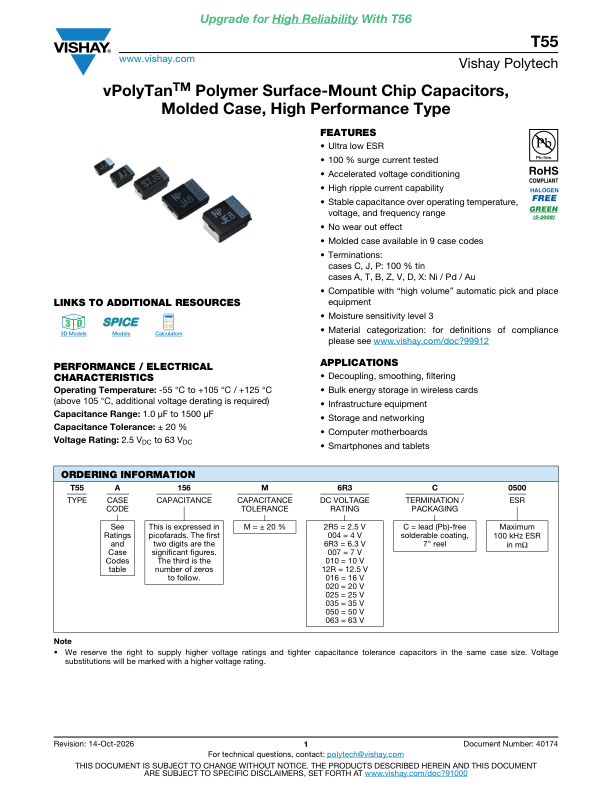

vishay_t55 | PDF 2쪽 원문임


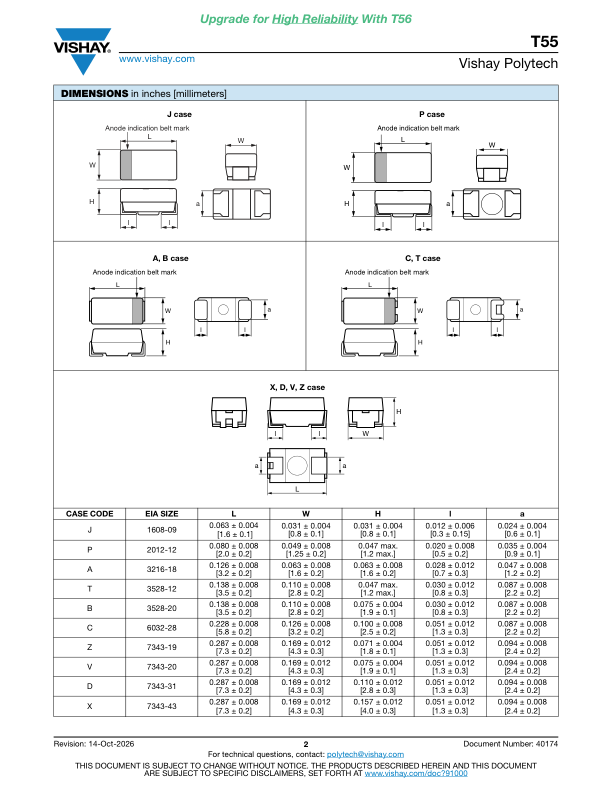

vishay_t55 | PDF 5쪽 원문임


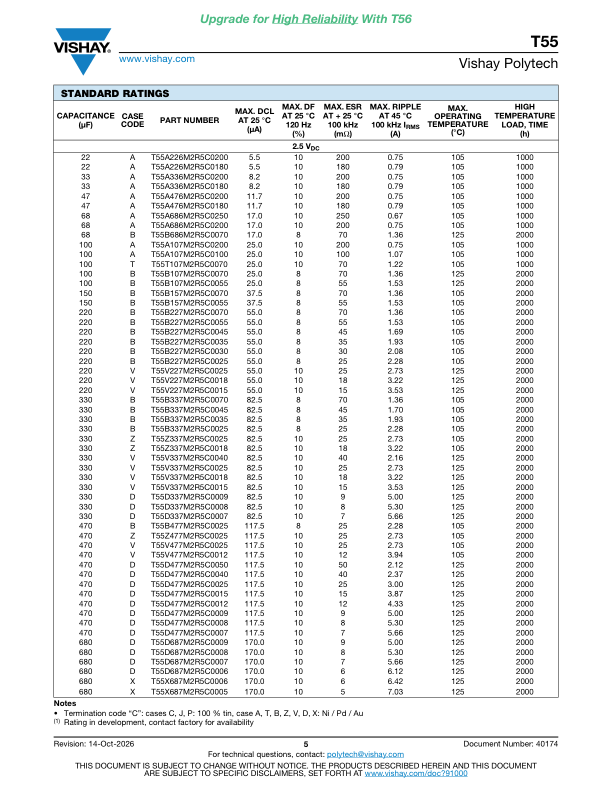

kyocera_avx_tcj | PDF 1쪽 원문임


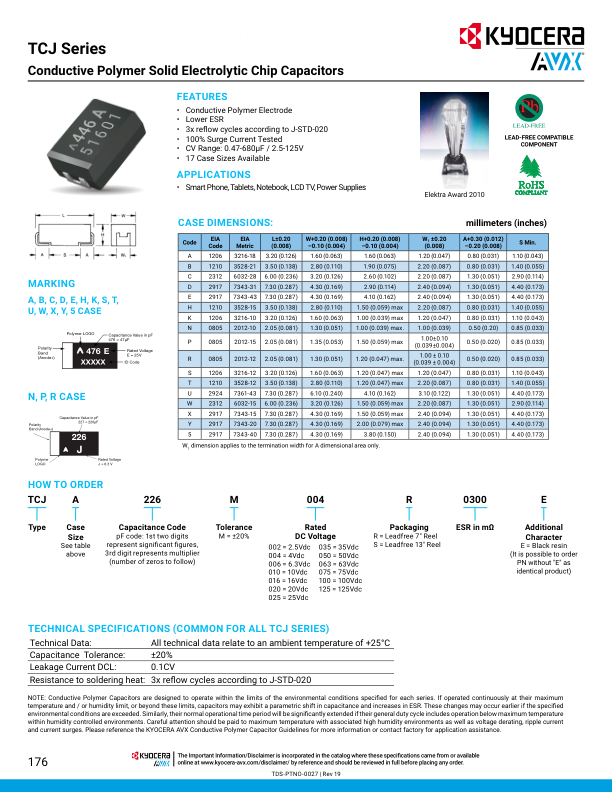

kyocera_avx_tcj | PDF 6쪽 원문임


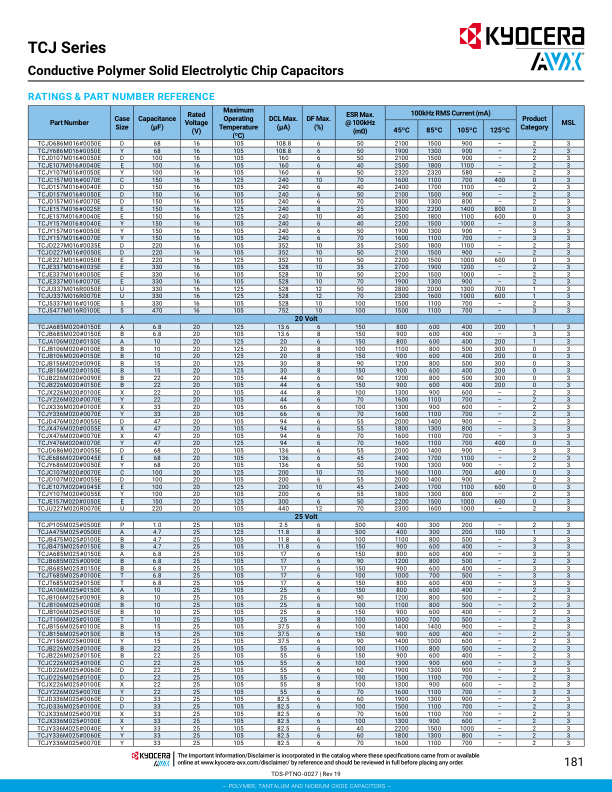

kyocera_avx_tcj | PDF 7쪽 원문임


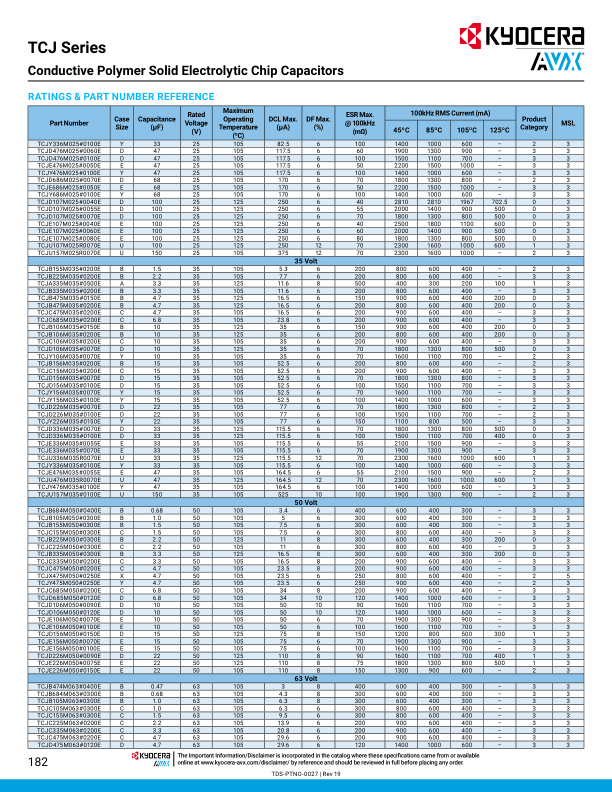

panasonic_tpb | PDF 1쪽 원문임


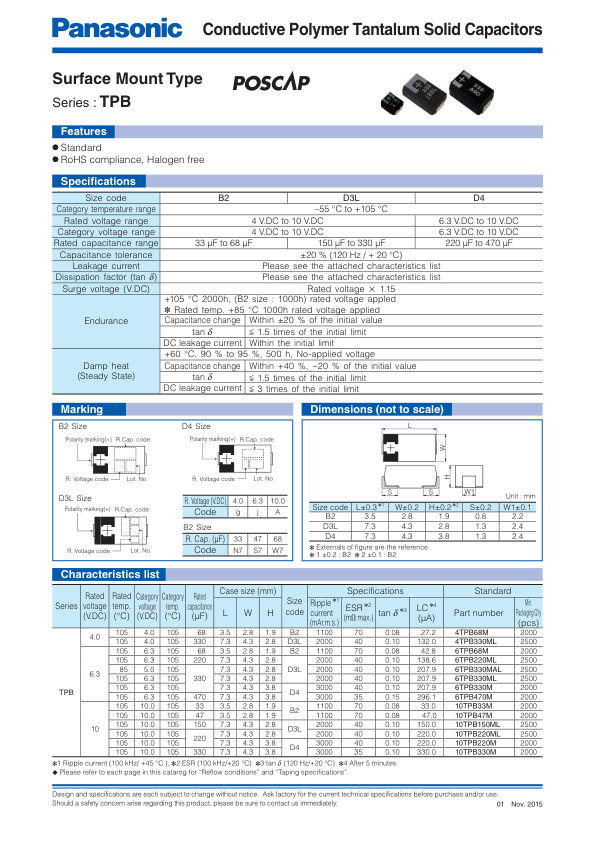

In [7]:
for document_id in SELECTED_IDS:
    with pymupdf.open(paths[document_id]) as document:
        for page_number in TABLE_PAGES[document_id]:
            print(f'{document_id} | PDF {page_number}쪽 원문임')
            pixmap = document[page_number - 1].get_pixmap(matrix=pymupdf.Matrix(1.0, 1.0), alpha=False)
            display(Image(data=pixmap.tobytes('png'), width=680))

In [8]:
table_shapes = []
row_candidates = []
for (document_id, tool, page), tables in table_cache.items():
    part_list = selected_parts.loc[selected_parts.document_id.eq(document_id), 'part_number'].tolist()
    for table_index, table in enumerate(tables, start=1):
        rows = table['rows']
        column_count = max((len(row) for row in rows), default=0)
        table_shapes.append({'document_id': document_id, 'tool': tool, 'page': page, 'table_index': table_index,
                             'rows': len(rows), 'columns': column_count, 'header_names': table['header_names']})
        print(f'\n{document_id} | {tool} | PDF {page}쪽 | 표 {table_index} | {len(rows)}행 {column_count}열')
        preview = [[None if cell is None else str(cell)[:160] for cell in row] for row in rows[:4]]
        display(pd.DataFrame(preview))
        for row_index, row in enumerate(rows, start=1):
            for part_number in part_list:
                matching_cells = [i + 1 for i, cell in enumerate(row)
                                  if cell is not None and part_number in re.sub(r'\s+', '', str(cell))]
                if matching_cells:
                    row_candidates.append({'document_id': document_id, 'tool': tool, 'page': page,
                                           'table_index': table_index, 'row_index': row_index,
                                           'part_number': part_number, 'matching_columns': matching_cells,
                                           'row_cells': row, 'validation_status': '수동 검토 필요함'})
table_shapes = pd.DataFrame(table_shapes)
row_candidates = pd.DataFrame(row_candidates)
print('표별 구조 요약임')
display(table_shapes)
print('P/N 포함 후보 행임. 규격 연결 검증 결과가 아님')
display(row_candidates)


vishay_t55 | PyMuPDF | PDF 1쪽 | 표 1 | 7행 15열


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,T55,A,,156,None,,M,NaN,,6R3,,C,,0500,None
1,TYPE,CASE\nCODE,,CAPACITANCE,None,,CAPACITANCE\nTOLERANCE,NaN,,DCVOLTAGE\nR ATING,,TERMINATION/\nPACKAGING,,ESR,None
2,,See,,Thisisexpressedin,None,,M=±,20%,,2R5 = 2 .5 V,,C = lead (Pb) -free,,Maximum,None
3,,Ratings\nand,,picofarads Thefirst\ntwodigits.\naret he,None,,,,,004=4V\n6R3 = 6 .3 V,,"solderablecoating\n,\n7""re el",,100kHzESR\ninmΩ,None



vishay_t55 | PyMuPDF | PDF 2쪽 | 표 1 | 11행 7열


,0,1,2,3,4,5,6
0,CASECODE,EIASIZE,L,W,H,l,a
1,J,1608 09\n-,0063±0004\n. .\n[16±01]\n. .,0031±0004\n. 0.\n[08 ± 1]\n. .,0031±0004\n. 0.\n[08 ± 1]\n. .,0012±0006\n. 01.\n[03 ± 5]\n. .,0024±0004\n. 0.\n[06 ± 1]\n. .
2,P,2012 12\n-,0080±0008\n. 0.\n[20 ± 2]\n. .,0049±0008\n. 0.\n[125 ± 2]\n. .,0047max\n[1. ax].\n2m\n. .,0020±0008\n. 0.\n[05 ± 2]\n. .,0035±0004\n. 0.\n[09 ± 1]\n. .
3,A,3216 18\n-,0126±0008\n. 0.\n[32 ± 2]\n. .,0063±0008\n. 0.\n[16 ± 2]\n. .,0063±0008\n. 0.\n[16 ± 2]\n. .,0028±0012\n. 0.\n[07 ± 3]\n. .,0047±0008\n. 0.\n[12 ± 2]\n. .



vishay_t55 | PyMuPDF | PDF 5쪽 | 표 1 | 58행 8열


,0,1,2,3,4,5,6,7
0,CAPACITANCE\n(μF),CASE\nCODE,PARTNUMBER,MAX DCL\n.\nAT25°C\n(μA),MAX DF MAX ESR\n. .\nAT25°C AT+25°C\n120Hz 100kHz\n(%) (mΩ),MAX RIPPLE\n.\nAT45°C\n100 kHz IRMS\n(A),MAX\n.\nOPERATING\nTEMPERATURE\n(°C),"HIGH\nTEMPERATURE\nLOAD TIME\n,\n(h)"
1,,,,,2 .5 VDC,,,
2,22,A,T55A226M2R5C0200,55\n.,10 200,075\n.,105,1000
3,22,A,T55A226M2R5C0180,55\n.,10 180,079\n.,105,1000


... (98 outputs left out)

표별 구조 요약임


,document_id,tool,page,table_index,rows,columns,header_names
0,vishay_t55,PyMuPDF,1,1,7,15,"[T55, A, , 156, None, , M, None, , 6R3, , C, , 0500, None]"
1,vishay_t55,PyMuPDF,2,1,11,7,"[CASECODE, EIASIZE, L, W, H, l, a]"
2,vishay_t55,PyMuPDF,5,1,58,8,"[CAPACITANCE\n(μF), CASE\nCODE, PARTNUMBER, MAX DCL\n.\nAT25°C\n(μA), MAX DF MAX ESR\n. .\nAT25°C AT+25°C\n120Hz 100kHz\n(%) (..."
3,vishay_t55,pdfplumber,1,1,2,1,None
4,vishay_t55,pdfplumber,2,1,1,2,None
5,vishay_t55,pdfplumber,2,2,15,8,None
6,vishay_t55,pdfplumber,2,3,1,2,None
7,vishay_t55,pdfplumber,2,4,2,1,None
8,vishay_t55,pdfplumber,2,5,1,2,None
9,vishay_t55,pdfplumber,2,6,2,2,None


P/N 포함 후보 행임. 규격 연결 검증 결과가 아님


,document_id,tool,page,table_index,row_index,part_number,matching_columns,row_cells,validation_status
0,vishay_t55,PyMuPDF,5,1,3,T55A226M2R5C0200,[3],"[22, A, T55A226M2R5C0200, 55\n., 10 200, 075\n., 105, 1000]",수동 검토 필요함
1,vishay_t55,PyMuPDF,5,1,5,T55A336M2R5C0200,[3],"[33, A, T55A336M2R5C0200, 82\n., 10 200, 075\n., 105, 1000]",수동 검토 필요함
2,vishay_t55,PyMuPDF,5,1,15,T55B107M2R5C0070,[3],"[100, B, T55B107M2R5C0070, 250\n., 8 70, 136\n., 125, 2000]",수동 검토 필요함
3,vishay_t55,pdfplumber,5,2,4,T55A226M2R5C0200,[1],[22 A T55A226M2R5C0200 5.5 10 200 0.75 105 1000\n22 A T55A226M2R5C0180 5.5 10 180 0.79 105 1000\n33 A T55A336M2R5C0200 8.2 10 ...,수동 검토 필요함
4,vishay_t55,pdfplumber,5,2,4,T55A336M2R5C0200,[1],[22 A T55A226M2R5C0200 5.5 10 200 0.75 105 1000\n22 A T55A226M2R5C0180 5.5 10 180 0.79 105 1000\n33 A T55A336M2R5C0200 8.2 10 ...,수동 검토 필요함
5,vishay_t55,pdfplumber,5,2,4,T55B107M2R5C0070,[1],[22 A T55A226M2R5C0200 5.5 10 200 0.75 105 1000\n22 A T55A226M2R5C0180 5.5 10 180 0.79 105 1000\n33 A T55A336M2R5C0200 8.2 10 ...,수동 검토 필요함
6,kyocera_avx_tcj,PyMuPDF,6,1,23,TCJU337M016R0050E,[1],"[TCJU337M016R0050E, U, 330, 16, 125, 528, 12, 50, 2800, 2000, 1300, 700, 1, 3]",수동 검토 필요함
7,kyocera_avx_tcj,PyMuPDF,6,1,24,TCJU337M016R0070E,[1],"[TCJU337M016R0070E, U, 330, 16, 125, 528, 12, 70, 2300, 1600, 1000, 600, 1, 3]",수동 검토 필요함
8,kyocera_avx_tcj,PyMuPDF,6,1,53,TCJU227M020R0070E,[1],"[TCJU227M020R0070E, U, 220, 20, 105, 440, 12, 70, 2300, 1600, 1000, –, 2, 3]",수동 검토 필요함
9,kyocera_avx_tcj,PyMuPDF,7,1,17,TCJU107M025R0070E,[1],"[TCJU107M025R0070E, U, 100, 25, 125, 250, 12, 70, 2300, 1600, 1000, 600, 1, 3]",수동 검토 필요함


## 정량 비교
- 텍스트 비교는 선정 문서의 전체 페이지 기준임.
- 표 개수와 표 처리 시간은 사전에 지정한 표 비교 페이지에 한정함.
- 문자 수·표 개수·P/N 검색 수는 정확도 점수가 아님.
- 문서 텍스트 시간은 열기·전체 페이지 추출·닫기를 포함한 회차별 시간의 중앙값임.
- 표 시간은 비교 페이지들의 추출 시간 합계를 회차별로 계산한 뒤 중앙값을 사용함.

In [9]:
summary_rows = []
for document_id in SELECTED_IDS:
    target_count = len(selected_parts.loc[selected_parts.document_id.eq(document_id)])
    for tool in TOOLS:
        pages = page_metrics.loc[page_metrics.document_id.eq(document_id) & page_metrics.tool.eq(tool)]
        tables = table_metrics.loc[table_metrics.document_id.eq(document_id) & table_metrics.tool.eq(tool)]
        detections = pn_locations.loc[pn_locations.document_id.eq(document_id) & pn_locations.tool.eq(tool)]
        text_times = document_trials.loc[document_trials.document_id.eq(document_id) & document_trials.tool.eq(tool), 'text_document_seconds']
        table_times = table_trials.loc[table_trials.document_id.eq(document_id) & table_trials.tool.eq(tool)].groupby('trial').table_seconds.sum()
        summary_rows.append({'document_id': document_id, 'tool': tool, 'total_pages': len(pages),
            'text_success_pages': int(pages.text_success.sum()), 'text_characters': int(pages.text_characters.sum()),
            'table_pages_examined': len(tables), 'table_count': int(tables.table_count.sum()),
            'target_pn_count': target_count, 'exact_pn_detected': int(detections.loc[detections.exact_match, 'part_number'].nunique()),
            'whitespace_removed_pn_detected': int(detections.part_number.nunique()),
            'text_document_seconds_median': float(text_times.median()),
            'text_document_seconds_min': float(text_times.min()), 'text_document_seconds_max': float(text_times.max()),
            'table_seconds_median': float(table_times.median()), 'repeats': REPEATS})
summary = pd.DataFrame(summary_rows)
display(summary)
print('표 비교 페이지별 결과임')
display(table_metrics)
print('회차별 문서 텍스트 시간임')
display(document_trials)

,document_id,tool,total_pages,text_success_pages,text_characters,table_pages_examined,table_count,target_pn_count,exact_pn_detected,whitespace_removed_pn_detected,text_document_seconds_median,text_document_seconds_min,text_document_seconds_max,table_seconds_median,repeats
0,vishay_t55,PyMuPDF,30,30,76976,3,3,3,3,3,0.105991,0.095900,0.148255,3.578097,3
1,vishay_t55,pdfplumber,30,30,76897,3,18,3,3,3,3.670710,3.623814,3.765834,0.740190,3
2,kyocera_avx_tcj,PyMuPDF,13,13,45697,3,5,4,4,4,0.086597,0.082817,0.090324,12.895751,3
3,kyocera_avx_tcj,pdfplumber,13,13,46362,3,8,4,4,4,6.584224,5.893415,7.084616,3.648492,3
4,panasonic_tpb,PyMuPDF,1,1,3334,1,2,3,3,3,0.010820,0.010323,0.011875,1.447176,3
5,panasonic_tpb,pdfplumber,1,1,3366,1,16,3,3,3,0.310176,0.280760,0.464653,0.395547,3


표 비교 페이지별 결과임


,document_id,tool,page,table_count,table_seconds_median,table_count_variants
0,kyocera_avx_tcj,PyMuPDF,1,3,2.707552,1
1,kyocera_avx_tcj,PyMuPDF,6,1,4.930824,1
2,kyocera_avx_tcj,PyMuPDF,7,1,4.869238,1
3,kyocera_avx_tcj,pdfplumber,1,4,0.842253,1
4,kyocera_avx_tcj,pdfplumber,6,2,1.442595,1
5,kyocera_avx_tcj,pdfplumber,7,2,1.141466,1
6,panasonic_tpb,PyMuPDF,1,2,1.447176,1
7,panasonic_tpb,pdfplumber,1,16,0.395547,1
8,vishay_t55,PyMuPDF,1,1,1.017280,1
9,vishay_t55,PyMuPDF,2,1,1.234820,1


회차별 문서 텍스트 시간임


,document_id,tool,trial,text_document_seconds
0,vishay_t55,PyMuPDF,1,0.148255
1,vishay_t55,pdfplumber,1,3.623814
2,kyocera_avx_tcj,PyMuPDF,1,0.086597
3,kyocera_avx_tcj,pdfplumber,1,5.893415
4,panasonic_tpb,PyMuPDF,1,0.010820
5,panasonic_tpb,pdfplumber,1,0.464653
6,vishay_t55,pdfplumber,2,3.670710
7,vishay_t55,PyMuPDF,2,0.095900
8,kyocera_avx_tcj,pdfplumber,2,6.584224
9,kyocera_avx_tcj,PyMuPDF,2,0.090324


## 시각화
- 실제 측정된 전체 텍스트 문자 수와 처리 시간 중앙값만 시각화함.
- 텍스트 시간과 표 시간은 서로 다른 측정 범위이므로 분리 표시함.
- `outputs/`에는 PNG 2개만 저장함. 표 개수 그래프는 품질 오해를 줄이기 위해 생략함.

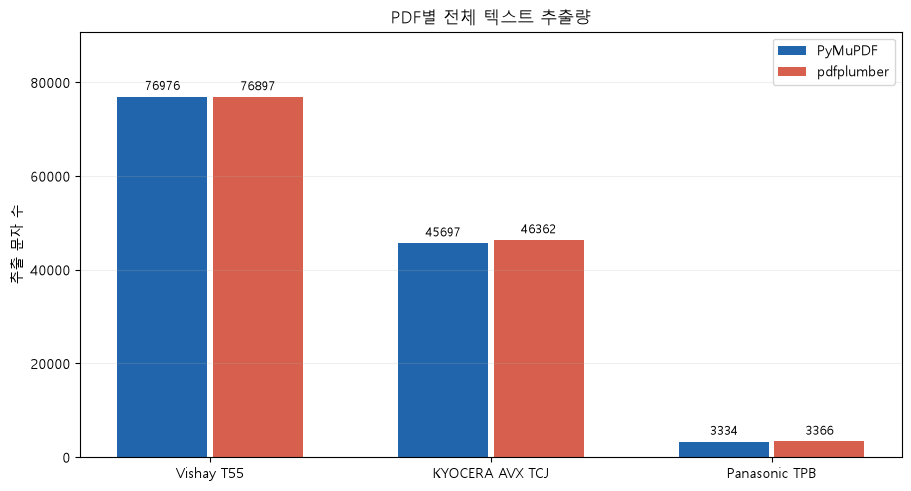

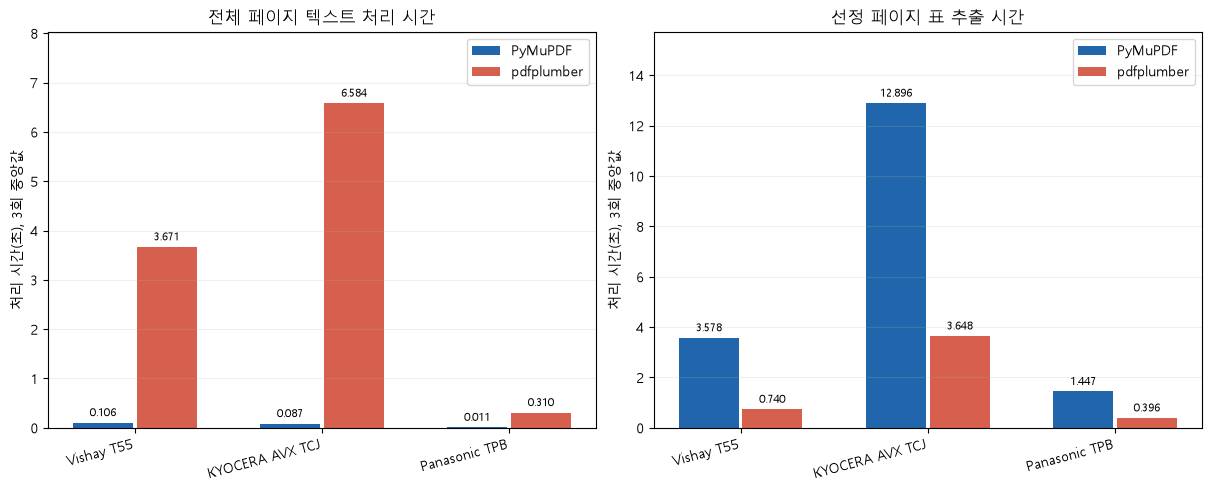

In [10]:
font_path = Path('C:/Windows/Fonts/malgun.ttf')
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams['axes.unicode_minus'] = False
colors = {'PyMuPDF': '#2166ac', 'pdfplumber': '#d6604d'}
labels = {'vishay_t55': 'Vishay T55', 'kyocera_avx_tcj': 'KYOCERA AVX TCJ', 'panasonic_tpb': 'Panasonic TPB'}

fig, ax = plt.subplots(figsize=(9, 4.8), layout='constrained')
for offset, tool in enumerate(TOOLS):
    values = summary.set_index(['document_id', 'tool']).loc[[(doc, tool) for doc in SELECTED_IDS], 'text_characters']
    positions = [index + (offset - 0.5) * 0.34 for index in range(len(SELECTED_IDS))]
    bars = ax.bar(positions, values, width=0.32, label=tool, color=colors[tool])
    ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=9)
ax.set_xticks(range(len(SELECTED_IDS)), [labels[doc] for doc in SELECTED_IDS])
ax.set_title('PDF별 전체 텍스트 추출량')
ax.set_ylabel('추출 문자 수')
ax.set_ylim(0, summary.text_characters.max() * 1.18)
ax.legend()
ax.grid(axis='y', alpha=0.2)
fig.savefig(OUTPUTS_DIR / '03_pdf_text_characters.png', dpi=160)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for ax, metric, title in zip(axes,
    ('text_document_seconds_median', 'table_seconds_median'),
    ('전체 페이지 텍스트 처리 시간', '선정 페이지 표 추출 시간')):
    for offset, tool in enumerate(TOOLS):
        values = summary.set_index(['document_id', 'tool']).loc[[(doc, tool) for doc in SELECTED_IDS], metric]
        positions = [index + (offset - 0.5) * 0.34 for index in range(len(SELECTED_IDS))]
        bars = ax.bar(positions, values, width=0.32, label=tool, color=colors[tool])
        ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    ax.set_xticks(range(len(SELECTED_IDS)), [labels[doc] for doc in SELECTED_IDS], rotation=15, ha='right')
    ax.set_title(title)
    ax.set_ylabel(f'처리 시간(초), {REPEATS}회 중앙값')
    ax.set_ylim(0, summary[metric].max() * 1.22)
    ax.legend()
    ax.grid(axis='y', alpha=0.2)
fig.savefig(OUTPUTS_DIR / '03_pdf_parsing_times.png', dpi=160)
plt.show()
plt.close(fig)

## 구조 검토 기준
- 아래 검토는 Codex가 원문 이미지와 기본 설정 추출 결과를 대조한 정성 기록임.
- A는 P/N별 개별 표 행, B는 시리즈 공통 규격, C는 주문 코드 설명에 해당함.
- A·B·C 구조의 존재와 특정 값의 적용·검증 통과를 구분함.
- 병합 헤더·빈 셀·측정 조건은 자동으로 확정하지 않으며 사용자 원문 대조가 필요함.

In [11]:
manual_review = pd.DataFrame([
    {'document_id': 'vishay_t55', 'pages': '1,2,5', 'structure': 'A/B/C',
     'pymupdf_observation': '5쪽에서 P/N 행을 분리하지만 DF·ESR 열이 합쳐지고 소수점이 숫자와 분리되는 사례가 있음',
     'pdfplumber_observation': '5쪽 기본 표 추출에서 규격표 본문이 한 열에 합쳐져 개별 행·열 관계 확인이 어려움',
     'connection_review': 'P/N 행 후보는 있으나 열 의미 손상이 있어 규격 자동 연결은 검증 불가로 기록함'},
    {'document_id': 'kyocera_avx_tcj', 'pages': '1,6,7', 'structure': 'A/B/C',
     'pymupdf_observation': '6·7쪽 P/N 행과 2단 헤더를 감지함. 일부 헤더 문자 순서가 어색하고 병합 셀이 None으로 남음',
     'pdfplumber_observation': '6·7쪽 P/N 행과 2단 헤더를 감지함. 장식 상자도 별도 표로 잡힘',
     'connection_review': '표 행 기반 연결 검토가 가능한 후보임. 병합 헤더·조건·각주 적용은 별도 수동 검토 필요함'},
    {'document_id': 'panasonic_tpb', 'pages': '1', 'structure': 'A/B',
     'pymupdf_observation': '공통 규격과 P/N 표를 감지하지만 헤더 오염·과도한 열 분할·소수점 분리 사례가 있음',
     'pdfplumber_observation': '장식 상자까지 다수 표로 잡히며 P/N 표 헤더 오염과 과도한 열 분할이 남음',
     'connection_review': 'P/N 후보 행 탐지는 가능하나 병합 셀·헤더 손상이 있어 규격 자동 연결은 검증 불가로 기록함'},
])
manual_review['reviewer'] = 'Codex 원문 대조임'
manual_review['user_verification'] = '사용자 직접 검토 대기 중임'
display(manual_review)
common_and_ordering_review = pd.DataFrame([
    {'document_id': 'vishay_t55', 'page': 1, 'common_scope_evidence': 'PERFORMANCE / ELECTRICAL CHARACTERISTICS 제목과 공통 범위 확인함',
     'ordering_evidence': 'ORDERING INFORMATION에서 항목별 코드 블록 확인함', 'limitation': '선정 P/N의 규격을 주문 예시에서 계산하거나 공통 범위를 개별 값으로 전파하지 않음'},
    {'document_id': 'kyocera_avx_tcj', 'page': 1, 'common_scope_evidence': 'TECHNICAL SPECIFICATIONS (COMMON FOR ALL TCJ SERIES) 제목 확인함',
     'ordering_evidence': 'HOW TO ORDER에서 항목별 코드와 설명 확인함', 'limitation': '다단 편집의 텍스트 읽기 순서만으로 코드와 설명을 자동 연결하지 않음'},
    {'document_id': 'panasonic_tpb', 'page': 1, 'common_scope_evidence': 'Series : TPB와 Specifications 표의 적용 범위 확인함',
     'ordering_evidence': '선정 페이지에서 전체 P/N 주문 코드 설명을 별도로 확인하지 못함', 'limitation': '공통 규격 표와 P/N별 표의 측정 조건을 자동으로 합치지 않음'},
])
display(common_and_ordering_review)
text_structure_review = pd.DataFrame([
    {'document_id': 'vishay_t55', 'pymupdf_text': '5쪽에서 제목·헤더·값이 여러 줄로 분리됨. 원래 행 관계가 텍스트 줄에 유지되지 않음',
     'pdfplumber_text': '5쪽에서 대상 P/N과 같은 행의 값이 한 줄에 유지됨. 다단 헤더는 여러 줄에 흩어짐'},
    {'document_id': 'kyocera_avx_tcj', 'pymupdf_text': '6·7쪽에서 P/N과 값이 개별 줄로 나뉨. 문서 페이지와 연결해 탐색 가능함',
     'pdfplumber_text': '6·7쪽에서 대상 P/N 행이 한 줄에 유지됨. 2단 헤더와 본문 표는 별도 확인 필요함'},
    {'document_id': 'panasonic_tpb', 'pymupdf_text': '1쪽에서 하단 면책 문구가 본문보다 먼저 나오는 등 화면 읽기 순서와 차이 있음',
     'pdfplumber_text': '행 단위 문맥은 비교 가능하지만 치수 그림과 별도 텍스트가 본문 읽기 순서에 섞임'},
])
text_structure_review['reviewer'] = 'Codex 원문 대조임'
text_structure_review['user_verification'] = '사용자 직접 검토 대기 중임'
display(text_structure_review)
print('표가 자동 감지되지 않은 비교 페이지 목록임')
display(table_metrics.loc[table_metrics.table_count.eq(0), ['document_id', 'tool', 'page']])
print('수동 검토 기록은 현재 라이브러리 버전과 문서 해시 기준임. 환경·파일 변경 시 재검토 필요함')


,document_id,pages,structure,pymupdf_observation,pdfplumber_observation,connection_review,reviewer,user_verification
0,vishay_t55,"1,2,5",A/B/C,5쪽에서 P/N 행을 분리하지만 DF·ESR 열이 합쳐지고 소수점이 숫자와 분리되는 사례가 있음,5쪽 기본 표 추출에서 규격표 본문이 한 열에 합쳐져 개별 행·열 관계 확인이 어려움,P/N 행 후보는 있으나 열 의미 손상이 있어 규격 자동 연결은 검증 불가로 기록함,Codex 원문 대조임,사용자 직접 검토 대기 중임
1,kyocera_avx_tcj,"1,6,7",A/B/C,6·7쪽 P/N 행과 2단 헤더를 감지함. 일부 헤더 문자 순서가 어색하고 병합 셀이 None으로 남음,6·7쪽 P/N 행과 2단 헤더를 감지함. 장식 상자도 별도 표로 잡힘,표 행 기반 연결 검토가 가능한 후보임. 병합 헤더·조건·각주 적용은 별도 수동 검토 필요함,Codex 원문 대조임,사용자 직접 검토 대기 중임
2,panasonic_tpb,1,A/B,공통 규격과 P/N 표를 감지하지만 헤더 오염·과도한 열 분할·소수점 분리 사례가 있음,장식 상자까지 다수 표로 잡히며 P/N 표 헤더 오염과 과도한 열 분할이 남음,P/N 후보 행 탐지는 가능하나 병합 셀·헤더 손상이 있어 규격 자동 연결은 검증 불가로 기록함,Codex 원문 대조임,사용자 직접 검토 대기 중임


,document_id,page,common_scope_evidence,ordering_evidence,limitation
0,vishay_t55,1,PERFORMANCE / ELECTRICAL CHARACTERISTICS 제목과 공통 범위 확인함,ORDERING INFORMATION에서 항목별 코드 블록 확인함,선정 P/N의 규격을 주문 예시에서 계산하거나 공통 범위를 개별 값으로 전파하지 않음
1,kyocera_avx_tcj,1,TECHNICAL SPECIFICATIONS (COMMON FOR ALL TCJ SERIES) 제목 확인함,HOW TO ORDER에서 항목별 코드와 설명 확인함,다단 편집의 텍스트 읽기 순서만으로 코드와 설명을 자동 연결하지 않음
2,panasonic_tpb,1,Series : TPB와 Specifications 표의 적용 범위 확인함,선정 페이지에서 전체 P/N 주문 코드 설명을 별도로 확인하지 못함,공통 규격 표와 P/N별 표의 측정 조건을 자동으로 합치지 않음


,document_id,pymupdf_text,pdfplumber_text,reviewer,user_verification
0,vishay_t55,5쪽에서 제목·헤더·값이 여러 줄로 분리됨. 원래 행 관계가 텍스트 줄에 유지되지 않음,5쪽에서 대상 P/N과 같은 행의 값이 한 줄에 유지됨. 다단 헤더는 여러 줄에 흩어짐,Codex 원문 대조임,사용자 직접 검토 대기 중임
1,kyocera_avx_tcj,6·7쪽에서 P/N과 값이 개별 줄로 나뉨. 문서 페이지와 연결해 탐색 가능함,6·7쪽에서 대상 P/N 행이 한 줄에 유지됨. 2단 헤더와 본문 표는 별도 확인 필요함,Codex 원문 대조임,사용자 직접 검토 대기 중임
2,panasonic_tpb,1쪽에서 하단 면책 문구가 본문보다 먼저 나오는 등 화면 읽기 순서와 차이 있음,행 단위 문맥은 비교 가능하지만 치수 그림과 별도 텍스트가 본문 읽기 순서에 섞임,Codex 원문 대조임,사용자 직접 검토 대기 중임


표가 자동 감지되지 않은 비교 페이지 목록임


,document_id,tool,page


수동 검토 기록은 현재 라이브러리 버전과 문서 해시 기준임. 환경·파일 변경 시 재검토 필요함


## 파싱 방식 권장안
- 선정한 문서에서는 pdfplumber 텍스트를 기본 입력 후보로 권장함. P/N 행 단위 문맥과 소수점 표기를 원문과 대조하기 쉬웠음.
- PyMuPDF는 빠른 페이지 탐색·원문 렌더링 보조 도구로 권장함. 텍스트 검색은 가능하지만 본 실험의 P/N 표에서는 각 값이 여러 줄로 나뉨.
- TCJ는 pdfplumber 표 결과를 보조 입력 후보로 사용할 수 있음. 병합 헤더·측정 조건·각주 확인 전 규격 검증 통과로 처리하지 않음.
- T55는 pdfplumber 텍스트의 행 문맥을 참고하되 기본 표 추출이 실패한 사례로 남김. PyMuPDF 표도 DF·ESR 열 합침과 소수점 분리가 있어 자동 대체하지 않음.
- TPB는 두 도구의 기본 표 추출 모두 헤더 오염·과도한 열 분할 문제가 있어 수동 검토 필요로 기록함.
- 속도는 텍스트 추출과 표 추출에서 우세한 도구가 달랐음. 처리 시간과 감지 표 개수를 품질 점수로 해석하지 않음.
- 주문 코드·시리즈 공통 규격은 원문 위치와 함께 보존하고 해당 P/N 적용 여부를 후속 단계에서 별도로 검토함.
- 이번 결과는 선정한 개발용 문서와 페이지에 한정함. 미선정 페이지·제조사 전체·평가용 PDF까지 지원된다고 판단하지 않음.
- 사용자 검토 전 권장안을 확정하거나 모듈·웹앱에 적용하지 않음.

## 결과 저장 및 무결성 확인
- 실험 요약 CSV 1개를 `results/`에 저장함. 상세 페이지별 시간·P/N 위치·원문·후보 행은 Notebook 출력에서 확인함.
- 원본 CSV와 선정 PDF의 해시가 실행 전후 같은지 확인함.
- 평가용 PDF는 CSV의 분리 정보만 확인했으며 파일을 열거나 해시를 읽지 않음.
- 출력 PNG 확인은 이번 Notebook이 생성한 파일에 한정함. 다른 기존 파일을 삭제하지 않음.

In [12]:
for filename, before in source_hashes.items():
    if hashlib.sha256(Path(filename).read_bytes()).hexdigest() != before:
        raise RuntimeError(f'원본 파일 변경 감지됨: {filename}')
expected_pngs = ('03_pdf_text_characters.png', '03_pdf_parsing_times.png')
for filename in expected_pngs:
    path = OUTPUTS_DIR / filename
    if path.read_bytes()[:8] != b'\x89PNG\r\n\x1a\n':
        raise ValueError(f'PNG 파일 확인 실패함: {path}')
summary_path = RESULTS_DIR / '03_pdf_parsing_summary.csv'
summary.to_csv(summary_path, index=False, encoding='utf-8')
reloaded = pd.read_csv(summary_path)
if len(reloaded) != len(summary) or list(reloaded.columns) != list(summary.columns):
    raise ValueError('저장된 실험 요약 CSV 확인 실패함')
print('원본 CSV와 선정 PDF 해시 유지 확인함')
print('평가용 PDF 열기 대상 없음:', sorted(paths))
print('실험 요약 저장함:', summary_path)
print('생성한 PNG 목록임:', list(expected_pngs))
print('사용자 직접 전체 실행·원문 대조는 대기 중임')
audit = {
    'environment': environment.to_dict('records'), 'summary': summary.to_dict('records'),
    'page_metrics': page_metrics.to_dict('records'), 'table_metrics': table_metrics.to_dict('records'),
    'pn_locations': pn_locations.to_dict('records'), 'table_shapes': table_shapes.to_dict('records'),
    'row_candidates': row_candidates.to_dict('records'), 'manual_review': manual_review.to_dict('records'),
    'text_samples': {f'{doc}|{tool}|{page}': text_cache[(doc, tool, page)][:1800]
                     for doc, page in sample_pages.items() for tool in TOOLS},
    'opened_document_ids': list(paths), 'source_hashes_unchanged': True,
}
display(JSON(audit, expanded=False))

PermissionError: [Errno 13] Permission denied: 'D:\\datasheet-assistant\\results\\03_pdf_parsing_summary.csv'